In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, confusion_matrix

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
import joblib
import time
import seaborn as sns
np.random.seed(42)

print("Ready to go!")

Ready to go!


In [2]:
df = pd.read_csv("manufacturing_dataset_1000_samples.csv")
print(df.head())
print(df.shape)


             Timestamp  Injection_Temperature  Injection_Pressure  Cycle_Time  \
0  2023-01-01 00:00:00                  221.0               136.0        28.7   
1  2023-01-01 01:00:00                  213.3               128.9        34.5   
2  2023-01-01 02:00:00                  222.8               115.9        19.9   
3  2023-01-01 03:00:00                  233.3               105.3        39.2   
4  2023-01-01 04:00:00                  212.2               125.5        45.0   

   Cooling_Time  Material_Viscosity  Ambient_Temperature  Machine_Age  \
0          13.6               375.5                 28.0          3.8   
1          14.0               215.8                 22.6          6.8   
2           9.5               307.0                 25.3          4.2   
3          13.1               137.8                 26.0          9.2   
4           9.9               298.2                 23.6          6.2   

   Operator_Experience  Maintenance_Hours    Shift Machine_Type  \
0      

In [3]:
print(df.isnull().sum())
print(df.dtypes)
print(df.shape)

Timestamp                      0
Injection_Temperature          0
Injection_Pressure             0
Cycle_Time                     0
Cooling_Time                   0
Material_Viscosity            20
Ambient_Temperature           20
Machine_Age                    0
Operator_Experience           20
Maintenance_Hours              0
Shift                          0
Machine_Type                   0
Material_Grade                 0
Day_of_Week                    0
Temperature_Pressure_Ratio     0
Total_Cycle_Time               0
Efficiency_Score               0
Machine_Utilization            0
Parts_Per_Hour                 0
dtype: int64
Timestamp                         str
Injection_Temperature         float64
Injection_Pressure            float64
Cycle_Time                    float64
Cooling_Time                  float64
Material_Viscosity            float64
Ambient_Temperature           float64
Machine_Age                   float64
Operator_Experience           float64
Maintenance_Hours 

In [11]:
print(df.columns.to_list())
df=df.drop_duplicates()
df["Material_Viscosity"]=df["Material_Viscosity"].fillna(df["Material_Viscosity"].median())
df["Ambient_Temperature"]=df["Ambient_Temperature"].fillna(df["Ambient_Temperature"].median())
df["Operator_Experience"]=df["Operator_Experience"].fillna(df["Operator_Experience"].median())
print("numerical missing values are filled")

df["Shift"]=df["Shift"].fillna(df["Shift"].mode())
df["Machine_Type"]=df["Machine_Type"].fillna(df["Machine_Type"].mode())
df["Material_Grade"]=df["Material_Grade"].fillna(df["Material_Grade"].mode())
df["Day_of_Week"]=df["Day_of_Week"].fillna(df["Day_of_Week"].mode())
print("categorical missing values are filled")


df = df.drop("Year", axis=1,errors="ignore")
df = df.drop("Minute", axis=1,errors="ignore")
df = df.drop("Second", axis=1,errors="ignore")
print("Time stamp set")

print(df.isnull().sum())
print(df.info)
print(df.dtypes)
print(df.head)

print("data is cleaned sucessfully")

['Timestamp', 'Injection_Temperature', 'Injection_Pressure', 'Cycle_Time', 'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature', 'Machine_Age', 'Operator_Experience', 'Maintenance_Hours', 'Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week', 'Temperature_Pressure_Ratio', 'Total_Cycle_Time', 'Efficiency_Score', 'Machine_Utilization', 'Parts_Per_Hour']
numerical missing values are filled
categorical missing values are filled
Time stamp set
Timestamp                     0
Injection_Temperature         0
Injection_Pressure            0
Cycle_Time                    0
Cooling_Time                  0
Material_Viscosity            0
Ambient_Temperature           0
Machine_Age                   0
Operator_Experience           0
Maintenance_Hours             0
Shift                         0
Machine_Type                  0
Material_Grade                0
Day_of_Week                   0
Temperature_Pressure_Ratio    0
Total_Cycle_Time              0
Efficiency_Score              0
Mac

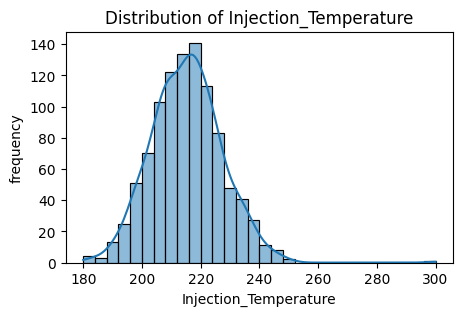

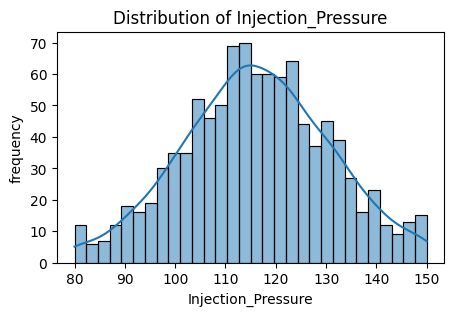

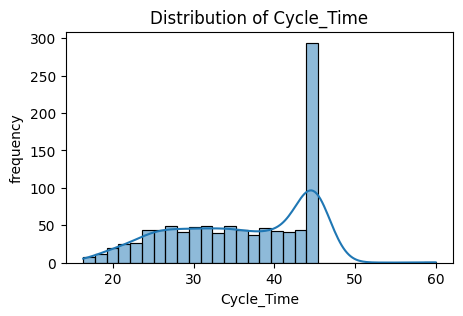

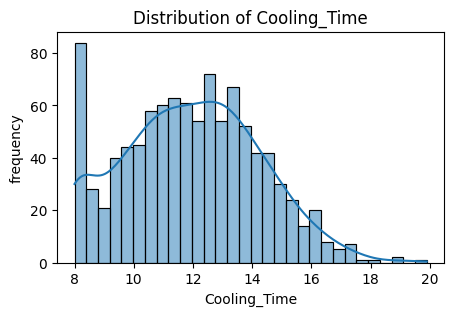

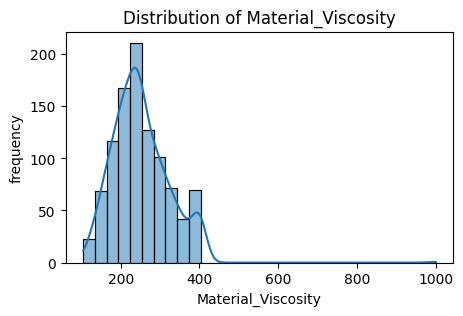

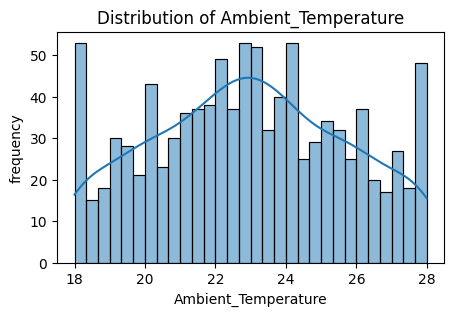

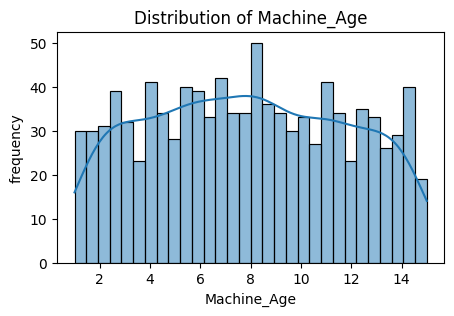

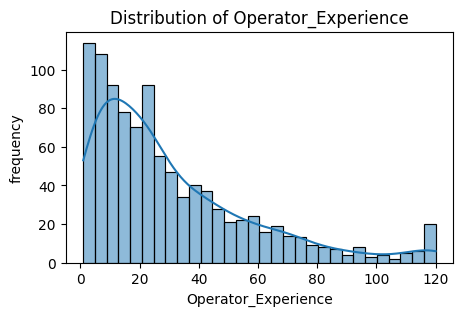

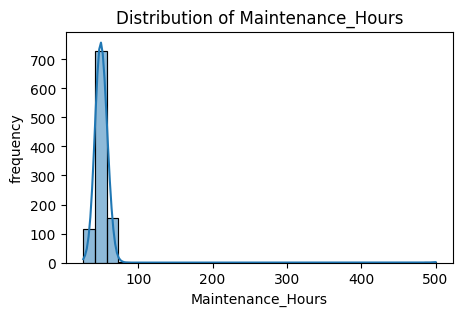

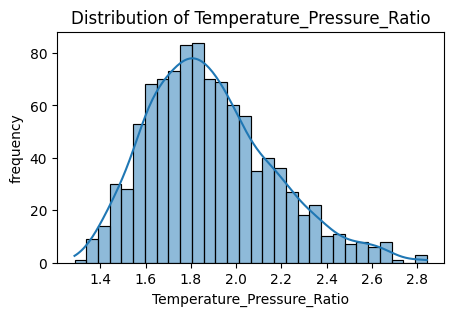

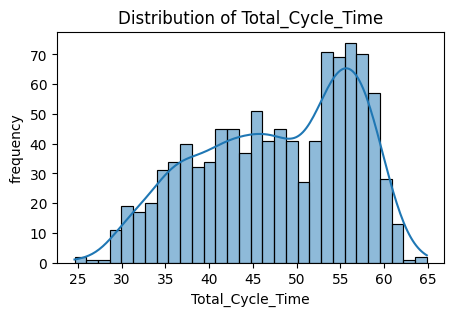

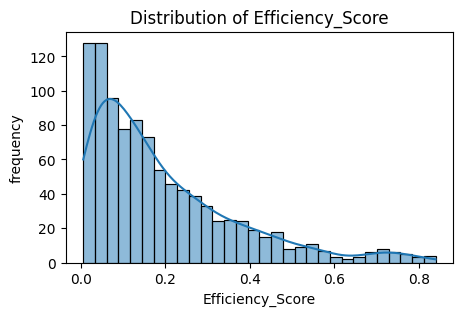

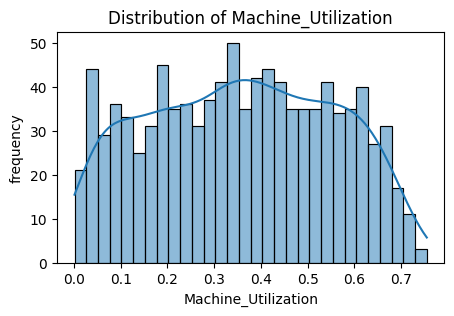

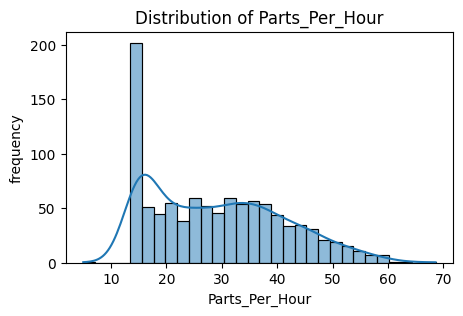

In [20]:
neumerical_columns=df.select_dtypes(include="number").columns

for column in neumerical_columns:
    plt.figure(figsize=(5,3))
    sns.histplot(df[column],kde=True,bins=30)

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("frequency")
    plt.show()


Correlation Matrix:
                             Injection_Temperature  Injection_Pressure  \
Injection_Temperature                    1.000000           -0.047187   
Injection_Pressure                      -0.047187            1.000000   
Cycle_Time                              -0.029448           -0.001274   
Cooling_Time                            -0.034085            0.008873   
Material_Viscosity                      -0.029703           -0.029052   
Ambient_Temperature                     -0.048356            0.020851   
Machine_Age                              0.062579           -0.025381   
Operator_Experience                      0.020429            0.027205   
Maintenance_Hours                       -0.025889           -0.009318   
Temperature_Pressure_Ratio               0.400671           -0.914916   
Total_Cycle_Time                        -0.042658            0.005126   
Efficiency_Score                         0.018696            0.023127   
Machine_Utilization           

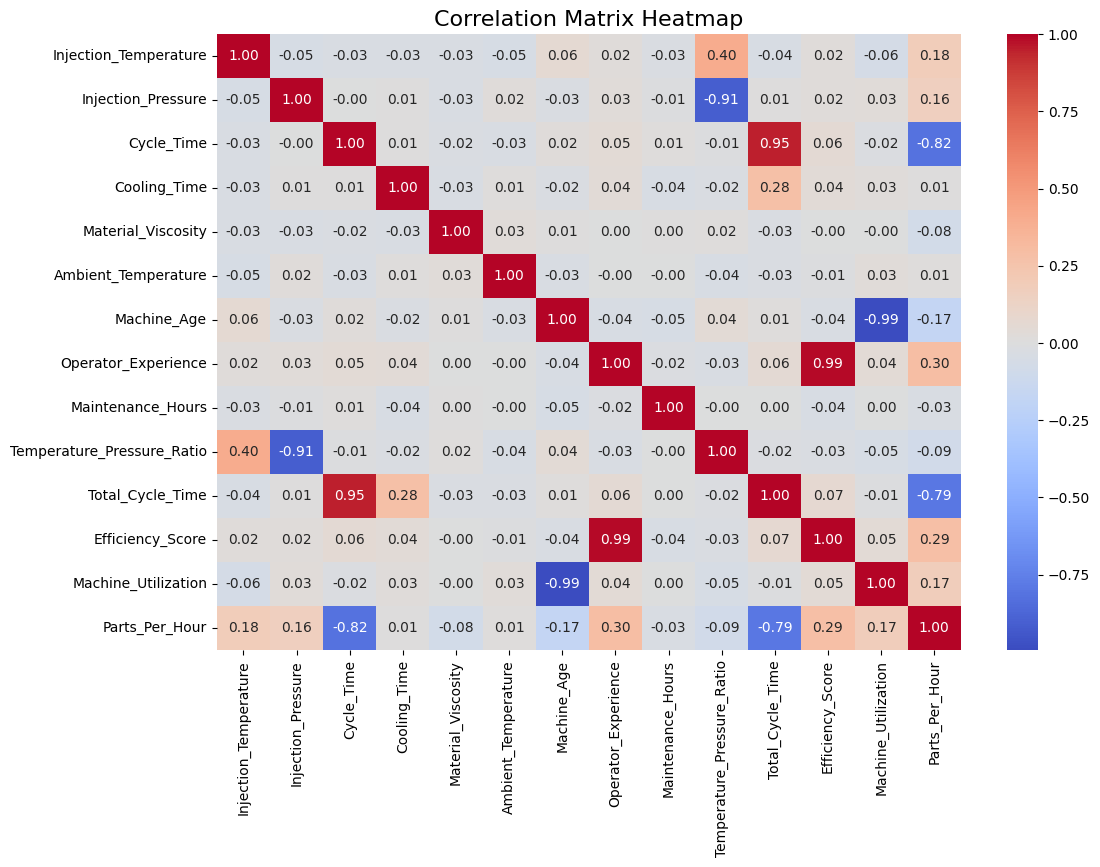

In [ ]:
corr_matrix = df.corr(numeric_only=True)
print("Correlation Matrix:\n", corr_matrix)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix Heatmap", fontsize=16)
plt.show()

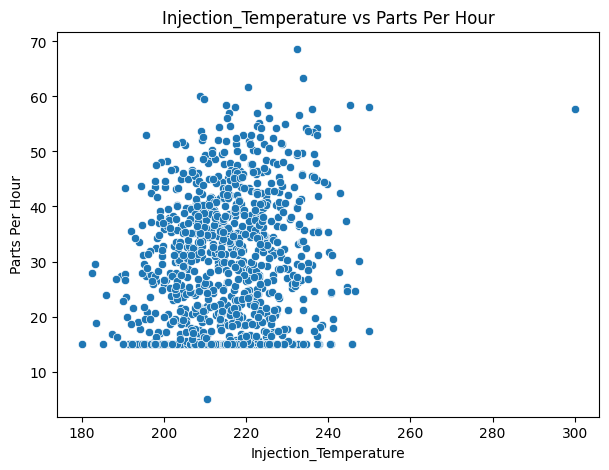

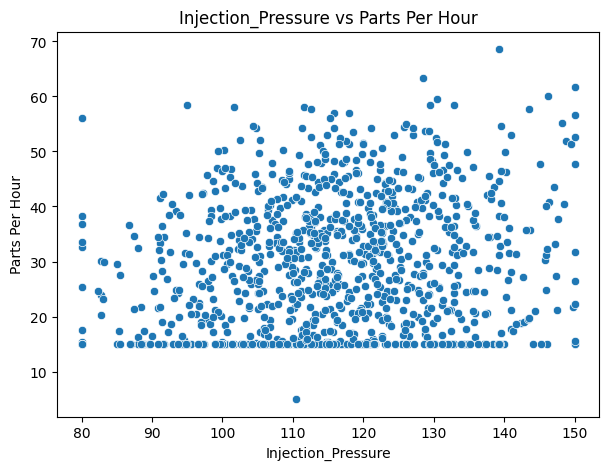

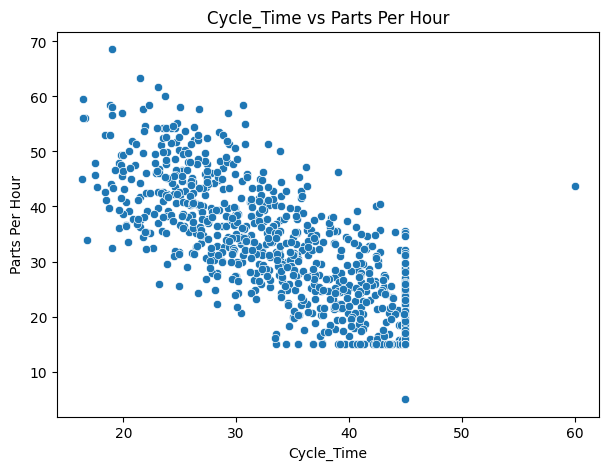

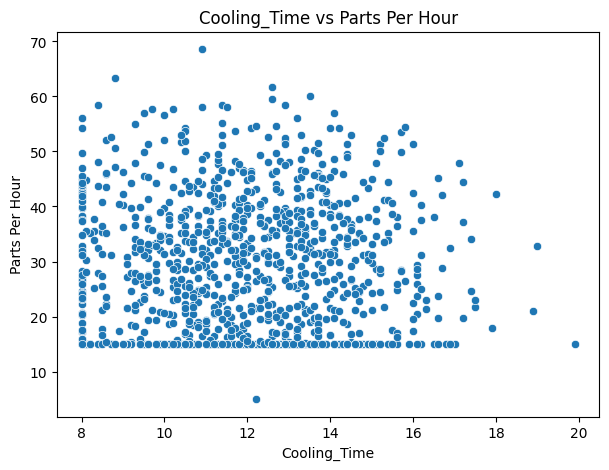

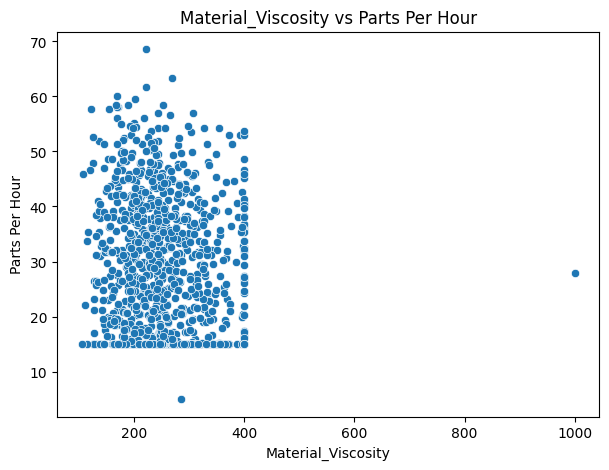

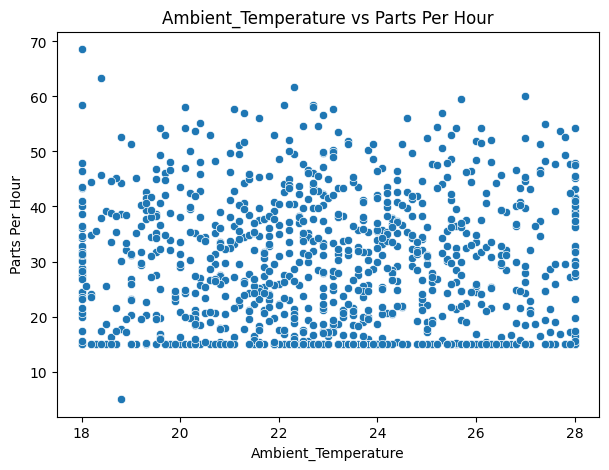

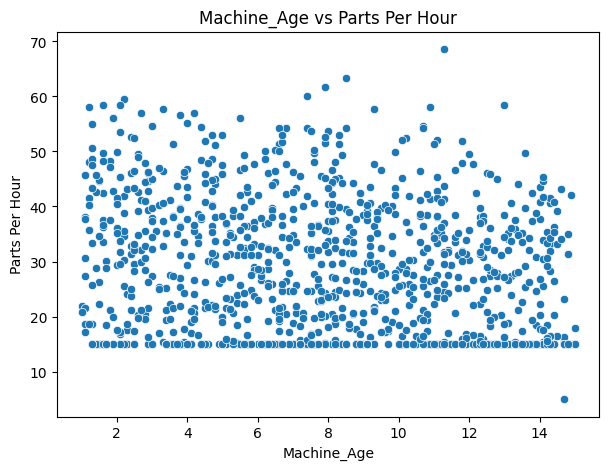

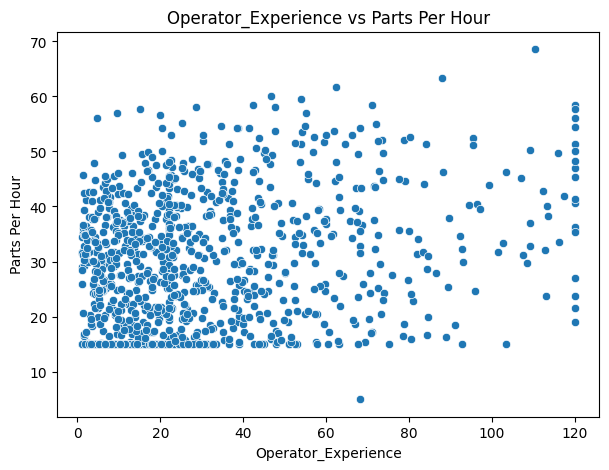

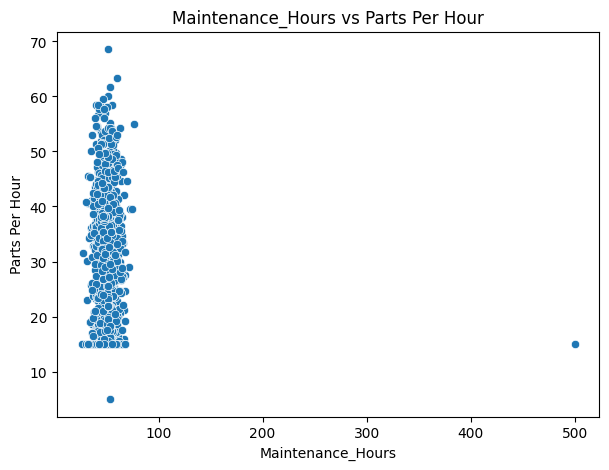

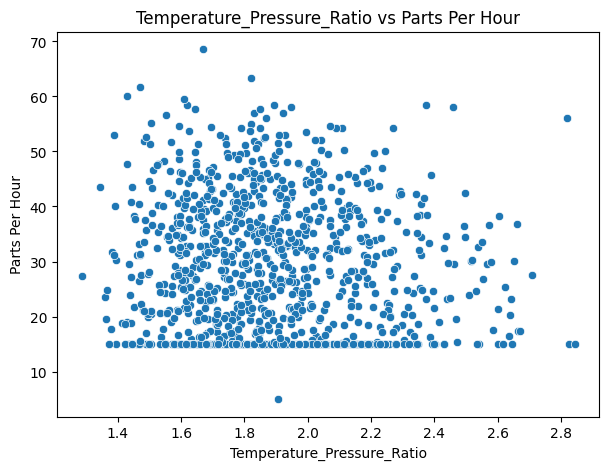

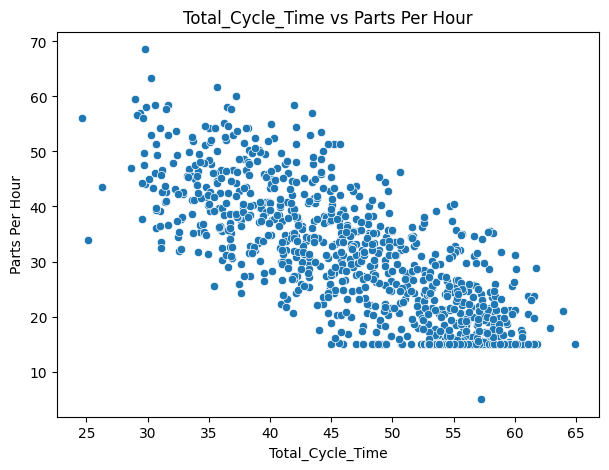

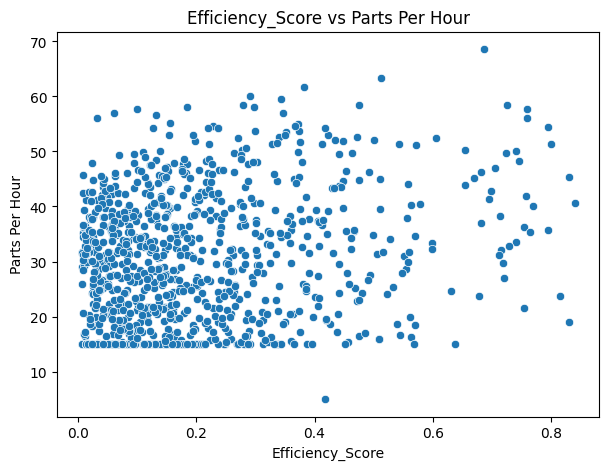

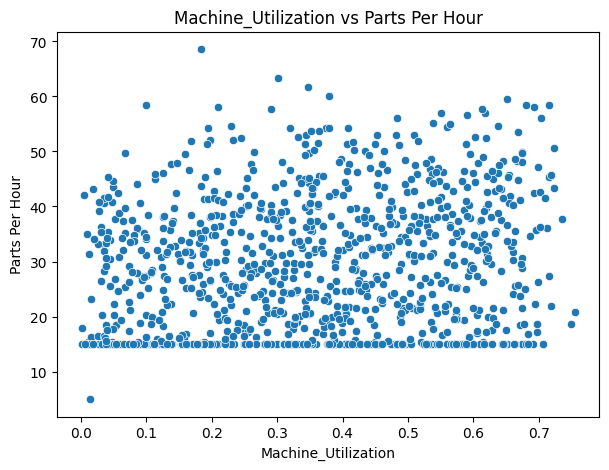

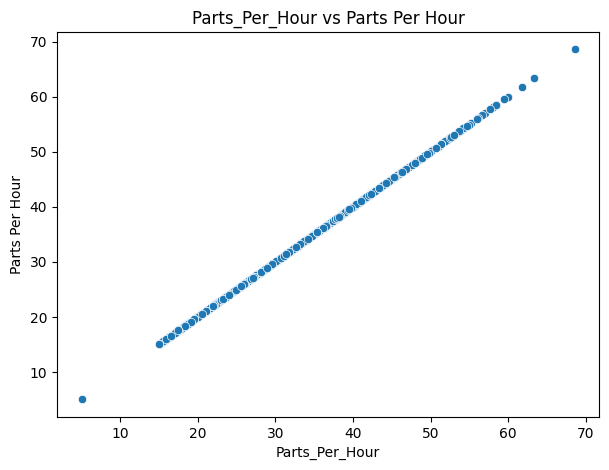

In [23]:
for col in neumerical_columns:
    plt.figure(figsize=(7,5))

    sns.scatterplot(
        x=df[col],
        y=df["Parts_Per_Hour"]
    )

    plt.title(f"{col} vs Parts Per Hour")
    plt.xlabel(col)
    plt.ylabel("Parts Per Hour")

    plt.show()

C:\Users\purna bandekar\AppData\Local\Temp\ipykernel_23672\3821704628.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Machine_Type', y='Parts_Per_Hour', ci=None, palette="viridis")
C:\Users\purna bandekar\AppData\Local\Temp\ipykernel_23672\3821704628.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Machine_Type', y='Parts_Per_Hour', ci=None, palette="viridis")


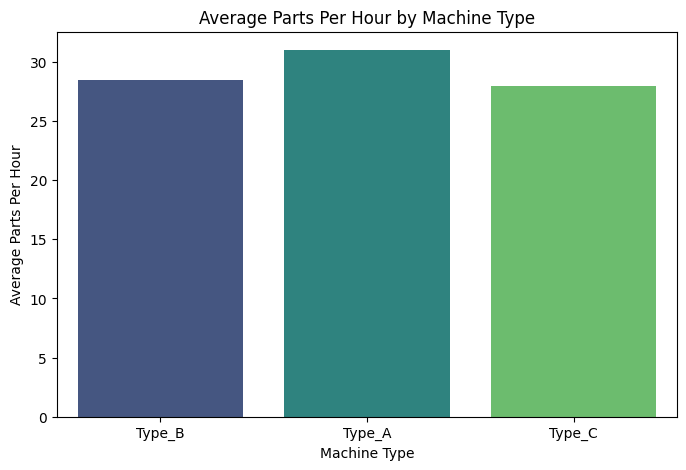

C:\Users\purna bandekar\AppData\Local\Temp\ipykernel_23672\3821704628.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Shift', y='Parts_Per_Hour', ci=None, palette="magma")
C:\Users\purna bandekar\AppData\Local\Temp\ipykernel_23672\3821704628.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Shift', y='Parts_Per_Hour', ci=None, palette="magma")


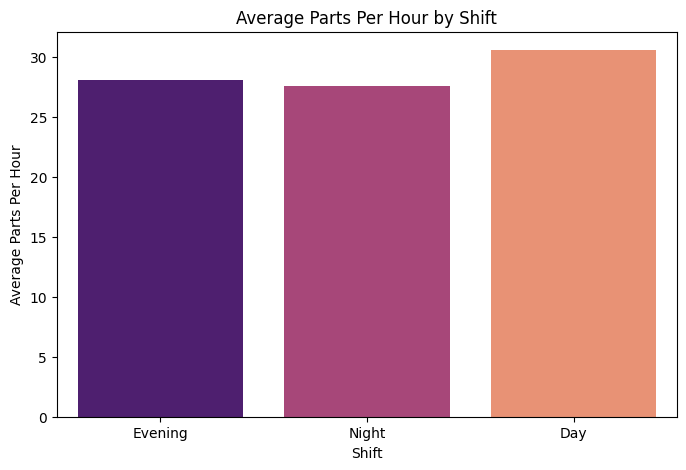

C:\Users\purna bandekar\AppData\Local\Temp\ipykernel_23672\3821704628.py:19: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Material_Grade', y='Parts_Per_Hour', ci=None, palette="coolwarm")
C:\Users\purna bandekar\AppData\Local\Temp\ipykernel_23672\3821704628.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Material_Grade', y='Parts_Per_Hour', ci=None, palette="coolwarm")


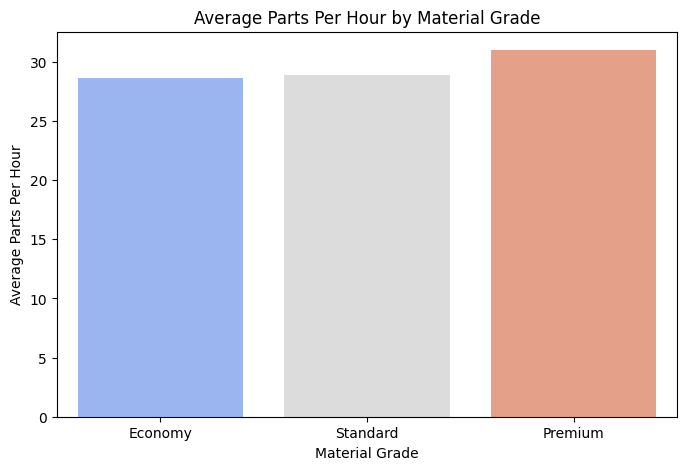

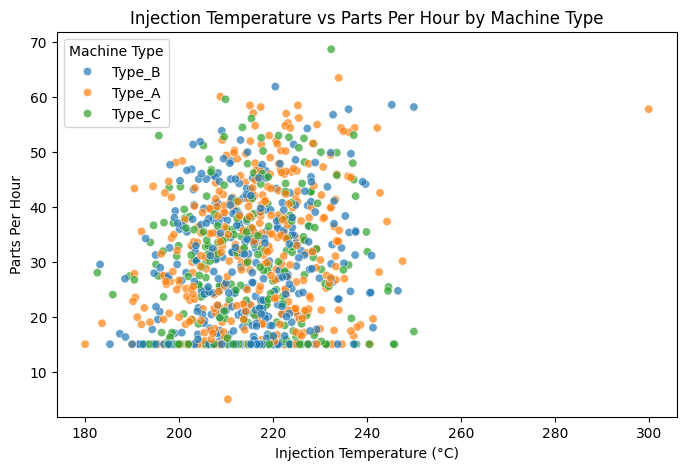

In [ ]:

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Machine_Type', y='Parts_Per_Hour', ci=None, palette="viridis")
plt.title("Average Parts Per Hour by Machine Type")
plt.ylabel("Average Parts Per Hour")
plt.xlabel("Machine Type")
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Shift', y='Parts_Per_Hour', ci=None, palette="magma")
plt.title("Average Parts Per Hour by Shift")
plt.ylabel("Average Parts Per Hour")
plt.xlabel("Shift")
plt.show()


plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Material_Grade', y='Parts_Per_Hour', ci=None, palette="coolwarm")
plt.title("Average Parts Per Hour by Material Grade")
plt.ylabel("Average Parts Per Hour")
plt.xlabel("Material Grade")
plt.show()

# 4. Relationship between Temperature and Pressure with production
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Injection_Temperature', y='Parts_Per_Hour', hue='Machine_Type', alpha=0.7)
plt.title("Injection Temperature vs Parts Per Hour by Machine Type")
plt.xlabel("Injection Temperature (°C)")
plt.ylabel("Parts Per Hour")
plt.legend(title="Machine Type")
plt.show()


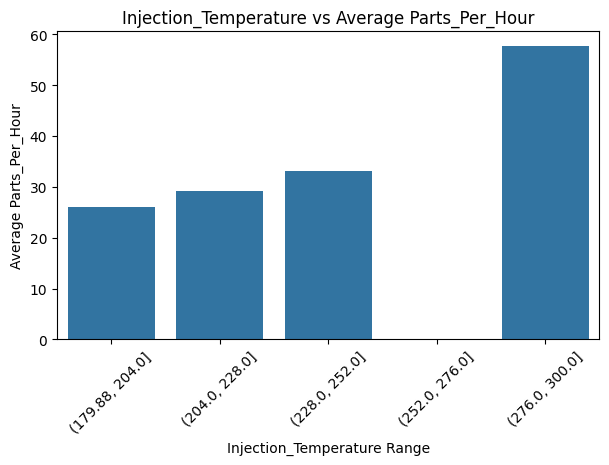

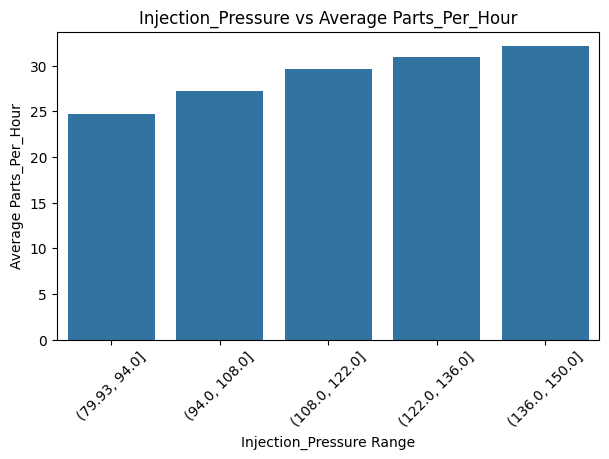

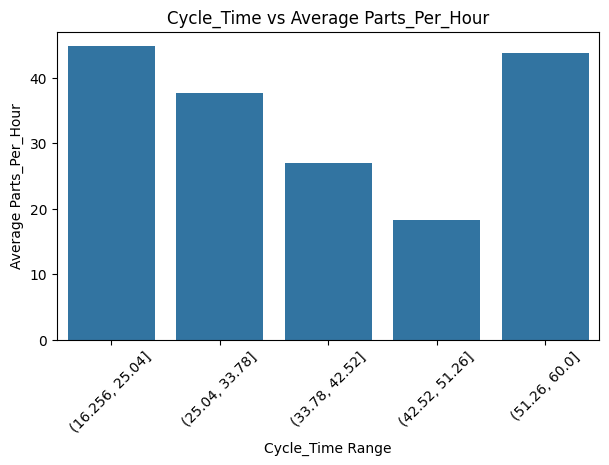

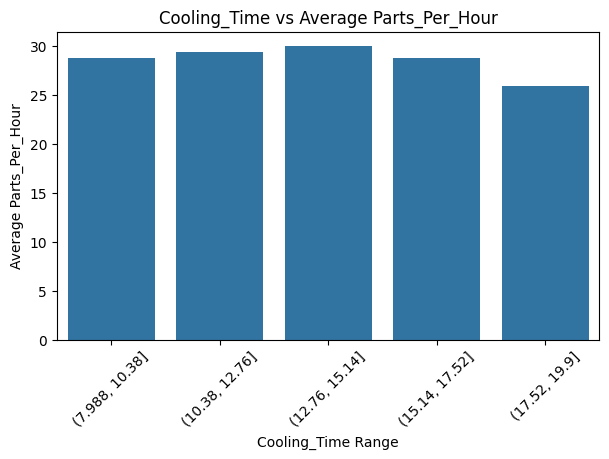

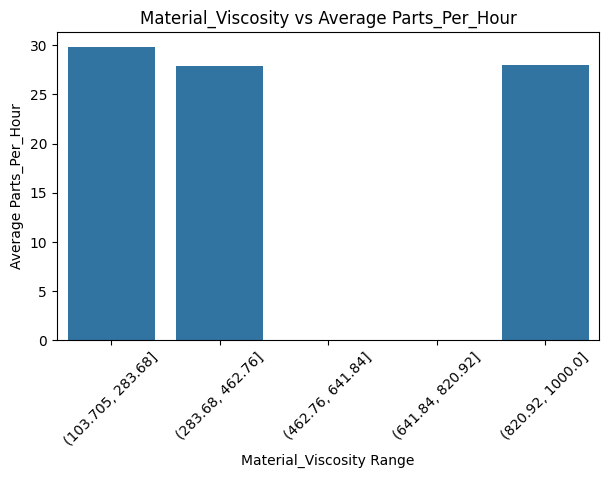

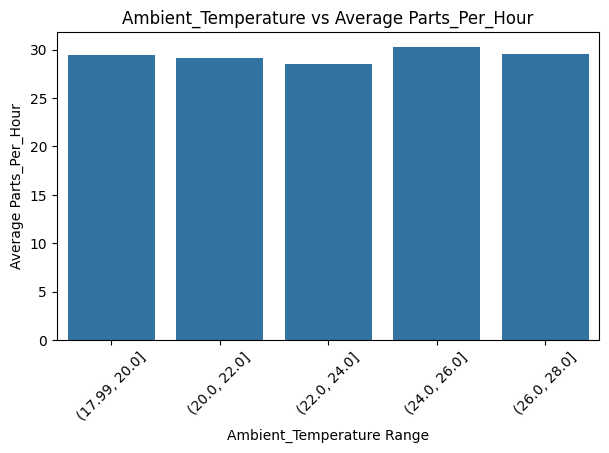

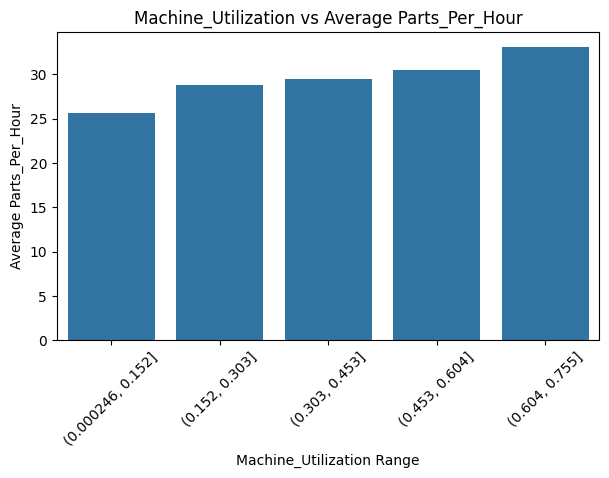

Optimal Operating Ranges:
Injection_Temperature: (276.0, 300.0] -> Avg Parts_Per_Hour = 57.70
Injection_Pressure: (136.0, 150.0] -> Avg Parts_Per_Hour = 32.09
Cycle_Time: (16.256, 25.04] -> Avg Parts_Per_Hour = 44.81
Cooling_Time: (12.76, 15.14] -> Avg Parts_Per_Hour = 29.93
Material_Viscosity: (103.705, 283.68] -> Avg Parts_Per_Hour = 29.84
Ambient_Temperature: (24.0, 26.0] -> Avg Parts_Per_Hour = 30.30
Machine_Utilization: (0.604, 0.755] -> Avg Parts_Per_Hour = 33.08


In [ ]:


target_var = 'Parts_Per_Hour'

# List of continuous operational parameters
params = [
    'Injection_Temperature',
    'Injection_Pressure',
    'Cycle_Time',
    'Cooling_Time',
    'Material_Viscosity',
    'Ambient_Temperature',
    'Machine_Utilization'
]

# Function to find optimal range
def find_optimal_ranges(df, param, bins=5):
    df['Range'] = pd.cut(df[param], bins=bins)
    range_summary = df.groupby('Range')[target_var].mean().reset_index()
    best_range = range_summary.loc[range_summary[target_var].idxmax()]
    return range_summary, best_range

optimal_results = {}

# Analyze and plot each parameter
for param in params:
    range_summary, best_range = find_optimal_ranges(df, param)
    optimal_results[param] = best_range
    
    plt.figure(figsize=(7, 4))
    sns.barplot(data=range_summary, x='Range', y=target_var)
    plt.title(f"{param} vs Average {target_var}")
    plt.ylabel(f"Average {target_var}")
    plt.xlabel(f"{param} Range")
    plt.xticks(rotation=45)
    plt.show()

# Display best ranges for each parameter
print("Optimal Operating Ranges:")
for param, best in optimal_results.items():
    print(f"{param}: {best['Range']} -> Avg {target_var} = {best[target_var]:.2f}")

In [32]:
#Step 4: Data Preprocessing and Feature Engineering
#Goal: Prepare data for optimal model performance

# Step 4.1 Handle any outliers using IQR method
# Handle outliers using IQR method

# Select numerical columns
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Function to remove outliers using IQR
def remove_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Filter rows within bounds
    return data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

# Remove outliers for each numerical column
df_clean = df.copy()
for col in numeric_cols:
    df_clean = remove_outliers_iqr(df_clean, col)

print(f"Original dataset shape: {df.shape}")
print(f"Cleaned dataset shape: {df_clean.shape}")

Original dataset shape: (1000, 20)
Cleaned dataset shape: (905, 20)


In [34]:
# Step 4.2 
# Create derived features that might be meaningful (e.g., efficiency ratios)
# Create derived features

df['Output_per_Cycle'] = df['Parts_Per_Hour'] / (3600 / df['Total_Cycle_Time'])
# How many parts are made in a single cycle on average

df['Cooling_to_Cycle_Ratio'] = df['Cooling_Time'] / df['Cycle_Time']
# Proportion of cycle time spent on cooling

df['Temp_Pressure_Efficiency'] = df['Injection_Temperature'] / df['Injection_Pressure']
# Another efficiency measure, similar to Temperature_Pressure_Ratio but for cross-check

df['Experience_per_MachineAge'] = df['Operator_Experience'] / df['Machine_Age']
# Operator experience relative to the machine's age

df['Maintenance_per_Part'] = df['Maintenance_Hours'] / (df['Parts_Per_Hour'] * 24)
# Maintenance effort relative to daily output

df['Utilization_to_Efficiency'] = df['Machine_Utilization'] / df['Efficiency_Score']
# How utilization compares to efficiency

print("New derived features created:")
print([col for col in df.columns if col not in numeric_cols and col not in ['Shift','Machine_Type','Material_Grade','Day_of_Week','Timestamp']])

New derived features created:
['Range', 'Output_per_Cycle', 'Cooling_to_Cycle_Ratio', 'Temp_Pressure_Efficiency', 'Experience_per_MachineAge', 'Maintenance_per_Part', 'Utilization_to_Efficiency']


In [35]:
# Step 4.3
# Scale features if necessary
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Select only numerical features (excluding target if needed)
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

# Optionally remove target variable from scaling
target_var = 'Parts_Per_Hour'
features_to_scale = [col for col in numeric_cols if col != target_var]

# Standard Scaling (mean=0, std=1)
scaler_standard = StandardScaler()
df_standard_scaled = df.copy()
df_standard_scaled[features_to_scale] = scaler_standard.fit_transform(df[features_to_scale])

# Min-Max Scaling (0 to 1)
scaler_minmax = MinMaxScaler()
df_minmax_scaled = df.copy()
df_minmax_scaled[features_to_scale] = scaler_minmax.fit_transform(df[features_to_scale])

print("Scaling complete.")
print(f"Standard scaled data sample:\n{df_standard_scaled[features_to_scale].head()}")
print(f"Min-Max scaled data sample:\n{df_minmax_scaled[features_to_scale].head()}")

Scaling complete.
Standard scaled data sample:
   Injection_Temperature  Injection_Pressure  Cycle_Time  Cooling_Time  \
0               0.474090            1.359149   -0.856562      0.728050   
1              -0.168139            0.874835   -0.161894      0.901726   
2               0.624221           -0.011937   -1.910541     -1.052130   
3               1.499987           -0.734998    0.401027      0.510955   
4              -0.259886            0.642910    1.095695     -0.878454   

   Material_Viscosity  Ambient_Temperature  Machine_Age  Operator_Experience  \
0            1.708997             1.843582    -1.040282            -0.708301   
1           -0.491176            -0.124033    -0.270824            -0.887005   
2            0.765278             0.859775    -0.937688            -0.766653   
3           -1.565775             1.114836     0.344743            -0.803123   
4            0.644042             0.240341    -0.424715            -0.277951   

   Maintenance_Hours  Tempe

In [ ]:
# Define features (X) and target (y)
target_var = 'Parts_Per_Hour'
X = df_clean.drop(columns=[target_var])
y = df_clean[target_var]

# Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (724, 19)
Testing set size: (181, 19)


In [40]:
# Impute numeric columns

# Identify numeric and non-numeric columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(exclude=['int64', 'float64']).columns

num_imputer = SimpleImputer(strategy="mean")
X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

# Impute categorical/date columns (most frequent)
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

# OPTIONAL: Drop non-numeric if model requires only numeric
X_train_model = X_train[num_cols]
X_test_model = X_test[num_cols]

# Train linear regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_model, y_train)

# Predict
y_pred = lin_reg.predict(X_test_model)

print("Model trained and predictions made!")

Model trained and predictions made!


---- Training Performance ----
R²:   0.8783
MSE:  16.0629
RMSE: 4.0079
MAE:  3.1883

---- Testing Performance ----
R²:   0.8910
MSE:  17.5449
RMSE: 4.1887
MAE:  3.3461


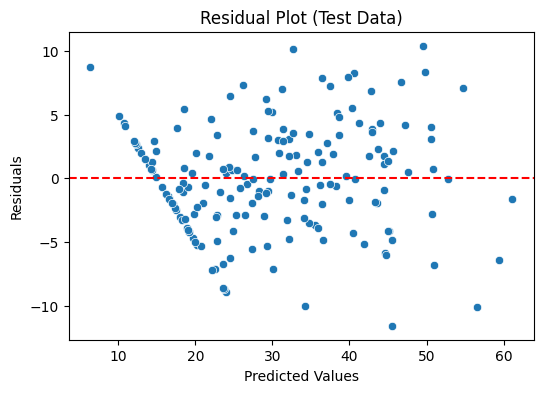

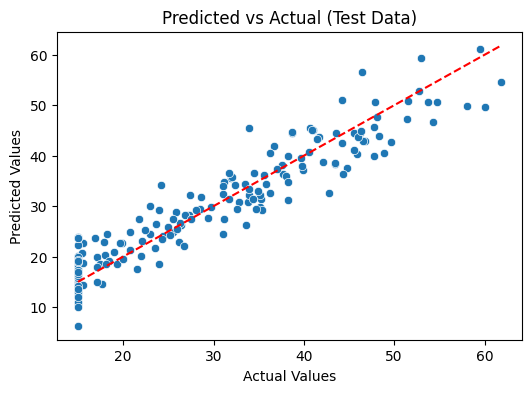

In [42]:
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def evaluate_model(model, X_train, y_train, X_test, y_test):
    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Training metrics
    r2_train = r2_score(y_train, y_train_pred)
    mse_train = mean_squared_error(y_train, y_train_pred)
    rmse_train = np.sqrt(mse_train)
    mae_train = mean_absolute_error(y_train, y_train_pred)

    # Testing metrics
    r2_test = r2_score(y_test, y_test_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)
    rmse_test = np.sqrt(mse_test)
    mae_test = mean_absolute_error(y_test, y_test_pred)

    # Print results
    print("---- Training Performance ----")
    print(f"R²:   {r2_train:.4f}")
    print(f"MSE:  {mse_train:.4f}")
    print(f"RMSE: {rmse_train:.4f}")
    print(f"MAE:  {mae_train:.4f}")

    print("\n---- Testing Performance ----")
    print(f"R²:   {r2_test:.4f}")
    print(f"MSE:  {mse_test:.4f}")
    print(f"RMSE: {rmse_test:.4f}")
    print(f"MAE:  {mae_test:.4f}")

    # ---- Residual plot ----
    residuals = y_test - y_test_pred
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=y_test_pred, y=residuals)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals")
    plt.title("Residual Plot (Test Data)")
    plt.show()

    # ---- Predicted vs Actual ----
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=y_test, y=y_test_pred)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title("Predicted vs Actual (Test Data)")
    plt.show()

# ---- Call evaluation function ----
evaluate_model(lin_reg, X_train_model, y_train, X_test_model, y_test)



In [45]:
# Get coefficients
feature_importance = pd.DataFrame({
    'Feature': X_train_model.columns,
    'Coefficient': lin_reg.coef_
})

# Add absolute values for ranking
feature_importance['Abs_Coefficient'] = np.abs(feature_importance['Coefficient'])

# Sort by absolute importance
feature_importance = feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

print("Feature impact ranking:")
print(feature_importance)

Feature impact ranking:
                       Feature  Coefficient  Abs_Coefficient
11            Efficiency_Score    14.933146        14.933146
9   Temperature_Pressure_Ratio    -8.999146         8.999146
3                 Cooling_Time     1.329281         1.329281
10            Total_Cycle_Time    -1.267857         1.267857
6                  Machine_Age    -0.444957         0.444957
0        Injection_Temperature     0.241039         0.241039
12         Machine_Utilization     0.232254         0.232254
7          Operator_Experience     0.082704         0.082704
5          Ambient_Temperature    -0.072346         0.072346
2                   Cycle_Time     0.060106         0.060106
8            Maintenance_Hours    -0.039084         0.039084
1           Injection_Pressure    -0.032159         0.032159
4           Material_Viscosity    -0.011656         0.011656


In [50]:
optimal_ranges = {}
for col in X_train_model.columns:
    Q1 = X_train_model[col].quantile(0.25)
    Q3 = X_train_model[col].quantile(0.75)
    optimal_ranges[col] = (Q1, Q3)

print("Suggested optimal operating ranges:")
for param, (low, high) in optimal_ranges.items():
    print(f"{param}: {low:.2f} – {high:.2f}")

Suggested optimal operating ranges:
Injection_Temperature: 206.90 – 222.62
Injection_Pressure: 106.57 – 126.40
Cycle_Time: 28.90 – 45.00
Cooling_Time: 10.30 – 13.43
Material_Viscosity: 201.85 – 296.32
Ambient_Temperature: 20.90 – 25.00
Machine_Age: 4.57 – 11.30
Operator_Experience: 9.70 – 37.95
Maintenance_Hours: 45.00 – 55.00
Temperature_Pressure_Ratio: 1.68 – 2.03
Total_Cycle_Time: 40.90 – 55.20
Efficiency_Score: 0.06 – 0.24
Machine_Utilization: 0.19 – 0.52


In [ ]:


print("Business Implications of Model Coefficients:")

for _, row in feature_importance.iterrows():
    feature = row['Feature']
    coefficient = row['Coefficient']

    if coefficient > 0:
        print(f"{feature} (Positive) → Increasing {feature} is associated with higher Parts Per Hour.")
    elif coefficient < 0:
        print(f"{feature} (Negative) → Increasing {feature} is associated with lower Parts Per Hour.")
    else:
        print(f"{feature} (Zero) → {feature} has little linear effect on Parts Per Hour.")

Business Implications of Model Coefficients:
Efficiency_Score (Positive) → Increasing Efficiency_Score is associated with higher Parts Per Hour.
Temperature_Pressure_Ratio (Negative) → Increasing Temperature_Pressure_Ratio is associated with lower Parts Per Hour.
Cooling_Time (Positive) → Increasing Cooling_Time is associated with higher Parts Per Hour.
Total_Cycle_Time (Negative) → Increasing Total_Cycle_Time is associated with lower Parts Per Hour.
Machine_Age (Negative) → Increasing Machine_Age is associated with lower Parts Per Hour.
Injection_Temperature (Positive) → Increasing Injection_Temperature is associated with higher Parts Per Hour.
Machine_Utilization (Positive) → Increasing Machine_Utilization is associated with higher Parts Per Hour.
Operator_Experience (Positive) → Increasing Operator_Experience is associated with higher Parts Per Hour.
Ambient_Temperature (Negative) → Increasing Ambient_Temperature is associated with lower Parts Per Hour.
Cycle_Time (Positive) → Incre